In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, norm, percentileofscore, fisher_exact, chi2_contingency, pearsonr, describe
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as patches
import pyBigWig
import re
import pysam

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.001_to1thresh0.999_cycle'+str(i)+'_CT20220329.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.001_to1thresh0.999_cycle'+str(i)+'_CT20220329.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [3]:
n_cycles, n_comps, n_DHSs = mixture_all_cycles.shape

In [4]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [5]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [6]:
tsv_file = open("/home/meuleman/work/projects/ENCODE3/WM20180608_733_sample_metadata/ENCODE 733-sample list WM20180608 - ENCODE3 metadata.tsv")
biosample_df2 = pd.read_csv(tsv_file, delimiter="\t")
biosample_df2 = biosample_df2.loc[0:732]

In [8]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
cycle0_dhs_int_arr = cycle0_dhs_arr.astype(int)
n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [9]:
num_biosamples = np.sum(cycle0_dhs_int_arr, axis=0)
num_DHSs = np.sum(cycle0_dhs_int_arr, axis=1)

In [10]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
DHS_max_signal_array = np.load(file)

In [11]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.001_to1thresh0.999_cycle'+str(i)+'_CT20220421.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [12]:
flipped_recon = np.append(added_recon_all_cycles[0], removed_recon_all_cycles[0])

In [13]:
#biosample and DHS inds
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

flipped_DHS_inds = np.append(added_DHS_inds, removed_DHS_inds)
flipped_biosample_inds = np.append(added_biosample_inds, removed_biosample_inds)

In [14]:
#new and old components
added_DHS_original_comps = mixture_all_cycles_top_comp[0, added_DHS_inds]
added_DHS_new_comps = mixture_all_cycles_top_comp[1, added_DHS_inds]
removed_DHS_original_comps = mixture_all_cycles_top_comp[0, removed_DHS_inds]
removed_DHS_new_comps = mixture_all_cycles_top_comp[1, removed_DHS_inds]

added_biosample_original_comps = basis_all_cycles_top_comp[0, added_biosample_inds]
added_biosample_new_comps = basis_all_cycles_top_comp[1, added_biosample_inds]
removed_biosample_original_comps = basis_all_cycles_top_comp[0, removed_biosample_inds]
removed_biosample_new_comps = basis_all_cycles_top_comp[1, removed_biosample_inds]

flipped_DHS_original_comps = np.append(added_DHS_original_comps, removed_DHS_original_comps)
flipped_DHS_new_comps = np.append(added_DHS_new_comps, removed_DHS_new_comps)
flipped_biosample_original_comps = np.append(added_biosample_original_comps, removed_biosample_original_comps)
flipped_biosample_new_comps = np.append(added_biosample_new_comps, removed_biosample_new_comps)

In [15]:
#delta vals
removed_delta_all_cycles = removed_recon_all_cycles[0] - 1
added_delta_all_cycles = added_recon_all_cycles[0]

flipped_delta = np.append(added_delta_all_cycles, removed_delta_all_cycles)

In [16]:
#number of biosamples/DHSs
added_num_biosamples = num_biosamples[added_DHS_inds]
removed_num_biosamples = num_biosamples[removed_DHS_inds]

added_num_DHSs = num_DHSs[added_biosample_inds]
removed_num_DHSs = num_DHSs[removed_biosample_inds]

flipped_num_biosamples = np.append(added_num_biosamples, removed_num_biosamples)
flipped_num_DHSs = np.append(added_num_DHSs, removed_num_DHSs)

In [17]:
#max signal
added_max_signal = DHS_max_signal_array[added_biosample_inds, added_DHS_inds]
removed_max_signal = DHS_max_signal_array[removed_biosample_inds, removed_DHS_inds]

flipped_max_signal = np.append(added_max_signal, removed_max_signal)

In [18]:
#finding minimum max signal for positive calls
flipped_min_max_signal = []
for dhs in np.append(added_DHS_inds, removed_DHS_inds):
    flipped_min_max_signal.append(np.min(DHS_max_signal_array[cycle0_dhs_arr[:, dhs], dhs]))
flipped_min_max_signal = np.array(flipped_min_max_signal)

In [19]:
flipped_added_v_removed = np.append(np.array(['Added']*len(added_biosample_inds)), np.array(['Removed']*len(removed_biosample_inds)))

In [20]:
#strip all lns of end char
all_biosample_lns = np.array(biosample_df['Altius Library ID'])
all_biosample_lns_stripped = []
for ln in all_biosample_lns:
    if ln[-1].isalpha():
        all_biosample_lns_stripped.append(ln[:-1])
    else:
        all_biosample_lns_stripped.append(ln)
all_biosample_lns_stripped = np.array(all_biosample_lns_stripped)

In [21]:
#removed calls
removed_DHS_identifiers = np.array(DHS_metadata.loc[removed_DHS_inds]['identifier'])

removed_biosample_ln_stripped = all_biosample_lns_stripped[removed_biosample_inds]

#need to test out with original notebook
identifier2chunk = {}
chunk2identifier = {}
f = open("/home/meuleman/projects/ENCODE3/WM20180608_construct_masterlist_733samples/masterlist_DHSs_733samples_WM20180608_all_chunkIDs2indexIDs.txt", "r")
c=0
doubles=False
for line in f:
    c+=1
    line = line.strip().split('\t')
    if len(line[0].split(';')) > 1:
        if doubles==False:
            line = [line[0].split(';')[0], line[1]]
            doubles=True
        else:
            line = [line[0].split(';')[1], line[1]]
            doubles=False
    identifier2chunk[line[0]] = line[1]
    chunk2identifier[line[1]] = line[0]
f.close()

# #finding the chunks of each removed DHS
# removed_DHS_chunks = np.array([])
# for identifier, i in zip(removed_DHS_identifiers, range(len(removed_DHS_identifiers))):
#     if i % 10000==0:
#         print(i)
#     removed_DHS_chunks = np.append(removed_DHS_chunks, identifier2chunk[identifier])

# DHS_inds_in_iden2chunk = np.nonzero(np.array(list(identifier2chunk.keys())) == removed_DHS_identifiers[:, None])
# removed_DHS_chunks = np.array(list(identifier2chunk.values()))[DHS_inds_in_iden2chunk]

In [20]:
# np.save('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_removed_DHS_chunks_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.npy', removed_DHS_chunks)

In [22]:
removed_DHS_chunks = np.load('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_removed_DHS_chunks_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.npy')

In [ ]:
# #for each removed call, finding the biosamples that contributed to the DHS and where the peak signal is
# removed_DHS_calls = []
# removed_DHS_original_peaks = []
# for chunk, i in zip(removed_DHS_chunks, range(len(removed_DHS_chunks))):
#     if i % 10000==0:
#         print(i) 
#     chunk_info = []
#     core_chunk = chunk.split('_')[0]
#     core_bed = open("/net/seq/data/projects/ENCODE3_publications/erynes/ENCODEpaper2017/SubsetOf733/masterLists/workdir/peaks_all/"+core_chunk+".bed", "r")
#     for line in core_bed:
#         line = line.strip().split('\t')
#         if line[-1]==chunk:
#             chunk_info.append(line)
#     chunk_info = np.array(chunk_info)
#     removed_DHS_calls.append(chunk_info)
#     removed_DHS_original_peaks.append(np.median(chunk_info[:, 6].astype(int)))
#     core_bed.close()
# removed_DHS_original_peaks = np.array(removed_DHS_original_peaks).astype(int)

In [24]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.pickle', 'wb')
# pickle.dump(removed_DHS_calls, pickle_out)
# pickle_out.close()

In [25]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.pickle', 'wb')
# pickle.dump(removed_DHS_original_peaks, pickle_out)
# pickle_out.close()

In [23]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.pickle', 'rb')
removed_DHS_calls=pickle.load(pickle_in)

In [24]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.001_to1thresh0.999_cycle1_CT20220512.pickle', 'rb')
removed_DHS_original_peaks=pickle.load(pickle_in)

In [25]:
DHS_identifiers = np.array(DHS_metadata['identifier'])

identifier2ind = {}
for i in range(len(DHS_identifiers)):
    identifier2ind[DHS_identifiers[i]] = i
    
all_ln_nums = np.array(biosample_df['Altius Library ID'])
all_ln_stripped = np.array([])
for ln in all_ln_nums:
    if ln[-1].isalpha():
        all_ln_stripped = np.append(all_ln_stripped, ln[:-1])
    else:
        all_ln_stripped = np.append(all_ln_stripped, ln)

def percentile_range(all_scores, score):
    num_scores = len(all_scores)
    sorted_scores = np.sort(all_scores)
    sorted_score_inds = np.where(sorted_scores==score)[0]
    high_rank = sorted_score_inds[-1]+1
    low_rank = sorted_score_inds[0]
    high_percentile = high_rank/num_scores*100
    low_percentile = low_rank/num_scores*100
    weight = 1/len(sorted_score_inds)
    return low_percentile, high_percentile, weight

#distances from each removed call peak to consesus peak
removed_max_distance_from_consensus = []
removed_scores = []
removed_score_percentiles = []
removed_distances = []
removed_distance_percentiles = []
removed_outside_cores = []

for chunk_info, removed_ln in zip(removed_DHS_calls, 
                                  removed_biosample_ln_stripped):
    
    #chunk
    chunk = chunk_info[0, -1]
    #peak location
    peak_location = np.median(chunk_info[:, 6].astype(int))
    #start and end of core region
    core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    core_start = core_95[0]
    core_end = core_95[1]
    DHS_ind = identifier2ind[chunk2identifier[chunk_info[0, 7]]]
    DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
    DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
    if core_start < DHS_start:
        core_start = DHS_start
    if core_end > DHS_end:
        core_end = DHS_end
    
    #all calls distance from consensus
    all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    
    #removed biosample local ind
    removed_inds = np.where(chunk_info==removed_ln)[0]
    
    #scores for all calls
    scores = chunk_info[:, 4].astype(float)
    
    #max distance from all calls to consensus peak
    max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
    removed_max_distance_from_consensus.append(max_distance_from_consensus)
    
    
    score_call = []
    score_percentile_call = []
    distance_call = []
    distance_percentile_call = []
    outside_core_call = []
    
    for removed_ind in removed_inds:
        removed_peak = chunk_info[removed_ind, 6].astype(int)
        if ((removed_peak < core_start) | (removed_peak > core_end)):
            outside_core_call.append('yes')
        else:
            outside_core_call.append('no')
        
        
        #distance of removed call from peak
        removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
        distance_call.append(removed_peak_distance_from_consensus)
        #percentile of distance
        distance_percentile_range = percentile_range(all_distances, removed_peak_distance_from_consensus)
        
        #score percentile
        score = chunk_info[removed_ind, 4].astype(float)
        score_call.append(score)
        #score percentile
        score_percentile_range = percentile_range(scores, score)
        
        #averaging percentiles
        average_distance_per = int(np.mean(distance_percentile_range[:2]))
        distance_percentile_call.append(average_distance_per)
        average_score_per = int(np.mean(score_percentile_range[:2]))
        score_percentile_call.append(average_score_per)
        
    removed_scores.append(score_call)
    removed_score_percentiles.append(score_percentile_call)
    removed_distances.append(distance_call)
    removed_distance_percentiles.append(distance_percentile_call)
    removed_outside_cores.append(outside_core_call)

**DataFrame Construction**

In [26]:
flipped_metadata_dict = {'biosample_ind' : flipped_biosample_inds, 
                         'DHS_ind' : flipped_DHS_inds, 
                         'recon_val' : flipped_recon, 
                         'delta_val' : flipped_delta, 
                         'added_v_removed' : flipped_added_v_removed, 
                         'num_biosamples_for_DHS' : flipped_num_biosamples, 
                         'num_DHSs_for_biosample' : flipped_num_DHSs, 
                         'biosample_original_comp' : flipped_biosample_original_comps, 
                         'biosample_new_comp' : flipped_biosample_new_comps, 
                         'DHS_original_comp' : flipped_DHS_original_comps, 
                         'DHS_new_comp' : flipped_DHS_new_comps,
                         'max_signal' : flipped_max_signal,
                         'min_max_signal_for_DHS' : flipped_min_max_signal,
                         'removed_score' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_score' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_score_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_score_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_distance' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_distance' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_distance_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'average_removed_distance_percentile' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_outside_core' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'summary_removed_outside_core' : np.array([np.nan]*len(flipped_biosample_inds)),
                         'removed_DHS_max_call_distance' : np.array([np.nan]*len(flipped_biosample_inds))}

flipped_metadata_df = pd.DataFrame(flipped_metadata_dict)

flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score'] = np.array(removed_scores, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_score_percentile'] = np.array(removed_score_percentiles, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance'] = np.array(removed_distances, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_distance_percentile'] = np.array(removed_distance_percentiles, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_outside_core'] = np.array(removed_outside_cores, dtype=object)
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'removed_DHS_max_call_distance'] = np.array(removed_max_distance_from_consensus)

average_removed_scores = []
for i in removed_scores:
    if len(i)>1:
        average_removed_scores.append(np.mean(i))
    else:
        average_removed_scores.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_score'] = np.array(average_removed_scores)

average_removed_score_percentiles = []
for i in removed_score_percentiles:
    if len(i)>1:
        average_removed_score_percentiles.append(np.mean(i))
    else:
        average_removed_score_percentiles.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_score_percentile'] = np.array(average_removed_score_percentiles)

average_removed_distances = []
for i in removed_distances:
    if len(i)>1:
        average_removed_distances.append(np.mean(i))
    else:
        average_removed_distances.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_distance'] = np.array(average_removed_distances)

average_removed_distance_percentiles = []
for i in removed_distance_percentiles:
    if len(i)>1:
        average_removed_distance_percentiles.append(np.mean(i))
    else:
        average_removed_distance_percentiles.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'average_removed_distance_percentile'] = np.array(average_removed_distance_percentiles)

summary_removed_outside_cores = []
for i in removed_outside_cores:
    if ((len(i)>1) & ('yes' in i) & ('no' in i)):
        summary_removed_outside_cores.append('yes and no')
    elif ((len(i)>1) & ('yes' in i) & ('no' not in i)):
        summary_removed_outside_cores.append('yes')
    elif ((len(i)>1) & ('yes' not in i) & ('no' in i)):
        summary_removed_outside_cores.append('no')
    else:
        summary_removed_outside_cores.append(i[0])
flipped_metadata_df.loc[flipped_metadata_df['added_v_removed']=='Removed', 'summary_removed_outside_core'] = np.array(summary_removed_outside_cores)

In [27]:
pd.set_option('display.max_columns', None)

**Correlation Heatmaps**

In [28]:
flipped_metadata_df.corr(method='pearson', min_periods=1)

,biosample_ind,DHS_ind,recon_val,delta_val,num_biosamples_for_DHS,num_DHSs_for_biosample,biosample_original_comp,biosample_new_comp,DHS_original_comp,DHS_new_comp,max_signal,min_max_signal_for_DHS,average_removed_score,average_removed_score_percentile,average_removed_distance,average_removed_distance_percentile,removed_DHS_max_call_distance
biosample_ind,1.000000,-0.013834,0.169101,0.168347,0.075742,0.202058,0.203964,0.165812,0.067750,0.073704,-0.125458,-0.043960,-0.215679,-0.414154,0.112212,0.109958,0.047816
DHS_ind,-0.013834,1.000000,-0.004161,-0.004175,-0.020703,-0.004679,-0.011710,-0.005986,0.010592,0.010471,-0.021855,-0.033903,-0.003410,0.031031,-0.004734,0.001005,-0.010219
recon_val,0.169101,-0.004161,1.000000,0.998851,0.599850,0.641881,0.228633,0.256067,-0.274362,-0.261740,0.070101,-0.041189,0.050324,0.109806,-0.103234,-0.094750,-0.157591
delta_val,0.168347,-0.004175,0.998851,1.000000,0.608654,0.638496,0.224241,0.251807,-0.282196,-0.269958,0.068482,-0.038922,0.050324,0.109806,-0.103234,-0.094750,-0.157592
num_biosamples_for_DHS,0.075742,-0.020703,0.599850,0.608654,1.000000,0.189015,0.060335,0.083543,-0.504643,-0.501689,0.203405,0.152938,-0.033372,-0.246225,0.099473,0.092694,0.264052
num_DHSs_for_biosample,0.202058,-0.004679,0.641881,0.638496,0.189015,1.000000,0.229699,0.238456,-0.089153,-0.082291,-0.135250,-0.180725,-0.233316,-0.618816,0.087316,0.127006,0.080558
biosample_original_comp,0.203964,-0.011710,0.228633,0.224241,0.060335,0.229699,1.000000,0.967253,0.107727,0.123943,-0.024835,-0.087181,-0.040555,-0.217935,0.095169,0.086949,0.109091
biosample_new_comp,0.165812,-0.005986,0.256067,0.251807,0.083543,0.238456,0.967253,1.000000,0.090387,0.106962,-0.009975,-0.079648,-0.011115,-0.159151,0.080888,0.071608,0.111002
DHS_original_comp,0.067750,0.010592,-0.274362,-0.282196,-0.504643,-0.089153,0.107727,0.090387,1.000000,0.980935,-0.113838,-0.140746,-0.043000,-0.058841,0.032887,0.018654,-0.003415
DHS_new_comp,0.073704,0.010471,-0.261740,-0.269958,-0.501689,-0.082291,0.123943,0.106962,0.980935,1.000000,-0.113085,-0.143029,-0.042934,-0.059112,0.033505,0.019017,-0.002581


In [29]:
flipped_metadata_df_01 = flipped_metadata_df[(flipped_metadata_df['recon_val']<=0) | (flipped_metadata_df['recon_val']>=1)]

In [30]:
correlation_all_m = flipped_metadata_df.corr(method='pearson', min_periods=1)

<AxesSubplot:>

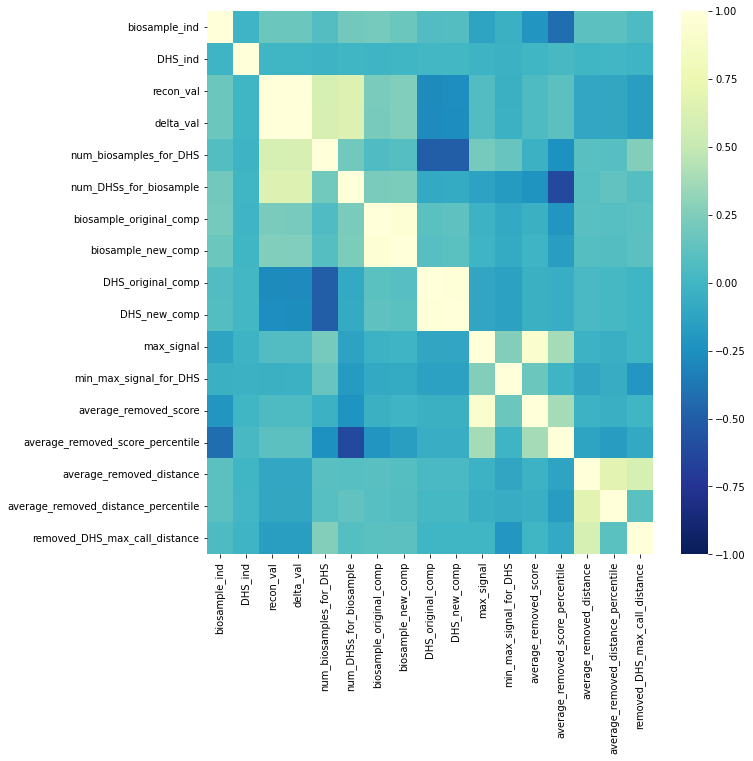

In [31]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

sns.heatmap(correlation_all_m, cmap="YlGnBu_r", vmin=-1, vmax=1)

In [32]:
correlation_01_m = flipped_metadata_df_01.corr(method='pearson', min_periods=1)

<AxesSubplot:>

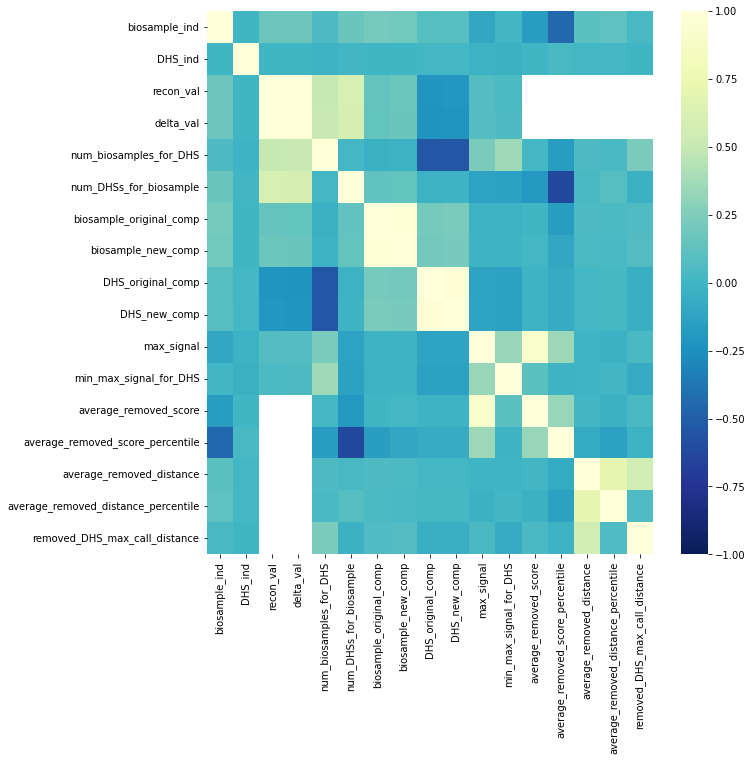

In [33]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

sns.heatmap(correlation_01_m, cmap="YlGnBu_r", vmin=-1, vmax=1)

**DHS annotation changes**

In [51]:
flipped_metadata_df_01[(flipped_metadata_df_01['added_v_removed']=='Removed') & 
                       (flipped_metadata_df_01['average_removed_distance_percentile']>50) & 
                       (flipped_metadata_df_01['average_removed_score_percentile']<50)]

,biosample_ind,DHS_ind,recon_val,delta_val,added_v_removed,num_biosamples_for_DHS,num_DHSs_for_biosample,biosample_original_comp,biosample_new_comp,DHS_original_comp,DHS_new_comp,max_signal,min_max_signal_for_DHS,removed_score,average_removed_score,removed_score_percentile,average_removed_score_percentile,removed_distance,average_removed_distance,removed_distance_percentile,average_removed_distance_percentile,removed_outside_core,summary_removed_outside_core,removed_DHS_max_call_distance
47572,403,1004809,0.0,-1.0,Removed,178,28298,0,0,5,5,0.401707,0.109184,[0.402782],0.402782,[32],32.0,[52.0],52.0,[83],83.0,[no],no,100.0
47578,403,1118780,0.0,-1.0,Removed,17,28298,0,0,5,5,0.964097,0.661101,[0.523616],0.523616,[32],32.0,[83.0],83.0,[73],73.0,[no],no,111.0
47581,570,2290276,0.0,-1.0,Removed,32,144047,1,1,2,2,0.390290,0.390290,[0.391706],0.391706,[1],1.0,[120.0],120.0,[98],98.0,[yes],yes,120.0
47582,403,1834157,0.0,-1.0,Removed,20,28298,0,0,5,5,0.522219,0.406327,[0.523616],0.523616,[17],17.0,[40.0],40.0,[77],77.0,[no],no,60.0
47585,673,419061,0.0,-1.0,Removed,10,40643,0,0,4,4,0.294113,0.183647,[0.27642],0.276420,[25],25.0,[70.0],70.0,[90],90.0,[no],no,70.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70007,99,981247,0.0,-1.0,Removed,128,61611,1,1,13,13,0.921014,0.159340,[0.835484],0.835484,[32],32.0,[20.0],20.0,[72],72.0,[no],no,60.0
70008,99,668304,0.0,-1.0,Removed,219,61611,1,1,13,13,0.745583,0.203750,[0.747538],0.747538,[20],20.0,[40.0],40.0,[82],82.0,[no],no,100.0
70015,133,900557,0.0,-1.0,Removed,43,57215,13,13,0,0,0.634168,0.147413,[0.604846],0.604846,[45],45.0,[60.0],60.0,[95],95.0,[yes],yes,80.0
70016,98,2418818,0.0,-1.0,Removed,44,225407,3,3,7,7,0.187827,0.146252,[0.193516],0.193516,[5],5.0,[130.0],130.0,[97],97.0,[yes],yes,130.0


In [56]:
flipped_metadata_df_01[(flipped_metadata_df_01['added_v_removed']=='Added') & 
                       (flipped_metadata_df_01['max_signal']>flipped_metadata_df_01['min_max_signal_for_DHS'])]

,biosample_ind,DHS_ind,recon_val,delta_val,added_v_removed,num_biosamples_for_DHS,num_DHSs_for_biosample,biosample_original_comp,biosample_new_comp,DHS_original_comp,DHS_new_comp,max_signal,min_max_signal_for_DHS,removed_score,average_removed_score,removed_score_percentile,average_removed_score_percentile,removed_distance,average_removed_distance,removed_distance_percentile,average_removed_distance_percentile,removed_outside_core,summary_removed_outside_core,removed_DHS_max_call_distance
0,455,2338142,1.931603,1.931603,Added,152,295314,11,11,11,11,5.792380,0.197591,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,455,2719105,1.839309,1.839309,Added,198,295314,11,11,11,11,6.885400,0.081822,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,455,2086593,1.795773,1.795773,Added,217,295314,11,11,11,11,3.939520,0.102589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,529,1342644,1.776905,1.776905,Added,160,252877,9,9,9,9,0.437305,0.043195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,456,2655459,1.773028,1.773028,Added,105,258512,11,11,11,11,1.056140,0.056646,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46838,570,1730676,1.000009,1.000009,Added,658,144047,1,1,0,0,3.307990,0.843393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46839,600,395436,1.000005,1.000005,Added,211,297421,7,7,2,2,0.328639,0.054128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46840,600,3224968,1.000005,1.000005,Added,25,297421,7,7,7,7,0.977036,0.335088,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46841,615,21027,1.000000,1.000000,Added,74,155741,14,14,14,14,0.689060,0.230496,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [119]:
#Looking only at DHSs that have good flips as determined above
removed_DHS_inds_good_flips = np.array(flipped_metadata_df_01[(flipped_metadata_df_01['added_v_removed']=='Removed') & 
                                                              (flipped_metadata_df_01['average_removed_distance_percentile']>50) & 
                                                              (flipped_metadata_df_01['average_removed_score_percentile']<50)]['DHS_ind'])

added_DHS_inds_good_flips = np.array(flipped_metadata_df_01[(flipped_metadata_df_01['added_v_removed']=='Added') & 
                                                            (flipped_metadata_df_01['max_signal']>flipped_metadata_df_01['min_max_signal_for_DHS'])]['DHS_ind'])

flipped_DHS_inds_good_flips = np.unique(np.append(added_DHS_inds_good_flips, removed_DHS_inds_good_flips))

In [135]:
##Using 01 threshold bases basis and mixtures


#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [136]:
#Mixture purity
mixture_cycle0_norm = (mixture_all_cycles[0, :, :]/np.sum(mixture_all_cycles[0, :, :], axis=0))
mixture_cycle0_norm_sorted = -np.sort(-mixture_cycle0_norm, axis=0)
mixture_cycle0_by_normdiff_purity = mixture_cycle0_norm_sorted[0, :] - mixture_cycle0_norm_sorted[1, :]

mixture_cycle1_norm = (mixture_all_cycles[1, :, :]/np.sum(mixture_all_cycles[1, :, :], axis=0))
mixture_cycle1_norm_sorted = -np.sort(-mixture_cycle1_norm, axis=0)
mixture_cycle1_by_normdiff_purity = mixture_cycle1_norm_sorted[0, :] - mixture_cycle1_norm_sorted[1, :]

Text(0.5, 1.0, 'Favorable Flips Result in More Pure Component Annotations')

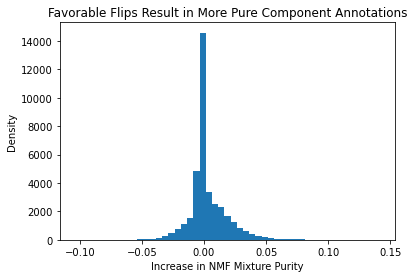

In [137]:
fig = plt.figure()
fig.patch.set_facecolor('white')

data = mixture_cycle1_by_normdiff_purity[flipped_DHS_inds_good_flips] - mixture_cycle0_by_normdiff_purity[flipped_DHS_inds_good_flips]

plt.hist(data, align='left', bins=np.arange(np.min(data), np.max(data), 0.005))
# plt.plot([0, 0], [0, 1])

# plt.xlim([-10, 10])
plt.xlabel('Increase in NMF Mixture Purity')
plt.ylabel('Density')
plt.title('Favorable Flips Result in More Pure Component Annotations')

Text(0.5, 1.0, 'Favorable Flips Result in More Pure Component Annotations')

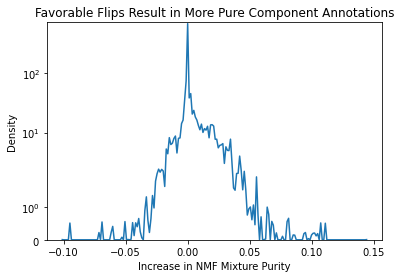

In [138]:
fig = plt.figure()
fig.patch.set_facecolor('white')

data = mixture_cycle1_by_normdiff_purity[flipped_DHS_inds_good_flips] - mixture_cycle0_by_normdiff_purity[flipped_DHS_inds_good_flips]

sns.kdeplot(data, bw_adjust=0.01)
# plt.plot([0, 0], [0, 1])

# plt.xlim([-10, 10])
plt.yscale('symlog')
plt.xlabel('Increase in NMF Mixture Purity')
plt.ylabel('Density')
plt.title('Favorable Flips Result in More Pure Component Annotations')

In [140]:
#finding good flip original and 
changed_dhss_all_cycles_flipbased_good_flips = []
changed_dhss_original_comp_flipbased_good_flips = []
changed_dhss_new_comp_flipbased_good_flips = []
    
for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[1], 
                             mixture_all_cycles_top_comp[0], 
                             range(len(mixture_all_cycles_top_comp[0]))):
    if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1)) and (dhs in flipped_DHS_inds_good_flips)):
        comp0 = comp0.astype(int)
        comp1 = comp1.astype(int)
        if ((dhs in removed_DHS_inds) | (dhs in added_DHS_inds)):
            changed_dhss_all_cycles_flipbased_good_flips.append(dhs)
            changed_dhss_original_comp_flipbased_good_flips.append(comp0)
            changed_dhss_new_comp_flipbased_good_flips.append(comp1)
            
changed_dhss_all_cycles_flipbased_good_flips = np.array(changed_dhss_all_cycles_flipbased_good_flips)
changed_dhss_original_comp_flipbased_good_flips = np.array(changed_dhss_original_comp_flipbased_good_flips)
changed_dhss_new_comp_flipbased_good_flips = np.array(changed_dhss_new_comp_flipbased_good_flips)

In [145]:
#using max signal from any biosample of the reassigned/original component - 5/27/22
original_comp_max_signal_any_biosample_flipbased_good_flips = np.array([])
new_comp_max_signal_any_biosample_flipbased_good_flips = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles_flipbased_good_flips[((changed_dhss_original_comp_flipbased_good_flips==original_comp) & 
                                                                     (changed_dhss_new_comp_flipbased_good_flips==new_comp))]
        #find biosamples
        original_biosamples = np.where(basis_all_cycles_top_comp[0]==original_comp)[0]
        new_biosamples = np.where(basis_all_cycles_top_comp[1]==new_comp)[0]
        #find max signal out of those biosamples for these DHSs
        original_max_signal = np.max(DHS_max_signal_array[:, changed_dhss][original_biosamples, :], axis=0)
        new_max_signal = np.max(DHS_max_signal_array[:, changed_dhss][new_biosamples, :], axis=0)
        original_comp_max_signal_any_biosample_flipbased_good_flips = np.append(original_comp_max_signal_any_biosample_flipbased_good_flips, original_max_signal)
        new_comp_max_signal_any_biosample_flipbased_good_flips = np.append(new_comp_max_signal_any_biosample_flipbased_good_flips, new_max_signal)
        
comp_max_signal_any_biosample_flipbased_good_flips_diff = new_comp_max_signal_any_biosample_flipbased_good_flips-original_comp_max_signal_any_biosample_flipbased_good_flips

Text(0.5, 1.0, 'Difference in Max Signal of Top Biosample of the Original\nand Reassigned Compoent for DHSs with Favorable Flips')

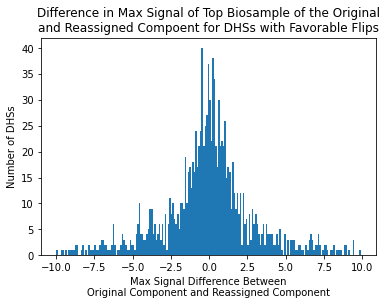

In [154]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(comp_max_signal_any_biosample_flipbased_good_flips_diff, 
         bins=np.arange(-10, 10, 0.1))

# plt.yscale('log')
plt.xlabel('Max Signal Difference Between\nOriginal Component and Reassigned Component')
plt.ylabel('Number of DHSs')
plt.title('Difference in Max Signal of Top Biosample of the Original\nand Reassigned Compoent for DHSs with Favorable Flips')